In [1]:
import ast
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image

from safetensors.torch import load_file
from transformers import AutoConfig, AutoModelForImageClassification

from pytorch_grad_cam import GradCAM, GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

In [2]:
label_to_id = pd.read_csv("Data/label_to_id_mapping.csv").set_index("label")["id"].to_dict()
dx=pd.read_csv("Data/Test_set.csv")

bboxes_frame = pd.read_csv("Data/collected_data.csv")
df=dx.copy()
label_mapping=pd.read_csv("Data/label_to_id_mapping.csv")

X=dx["X"].tolist()


dx["ID"]=dx["X"].str.split("/").str[-1]
dx["ID"]=dx["ID"].str.split(".").str[0]



In [3]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5],
    ),
])


In [4]:

model_dir = Path("best_model")


config = AutoConfig.from_pretrained(model_dir,local_files_only=True,)

classes = label_mapping["label"].tolist()



config.id2label = {i: label for i, label in enumerate(classes)}
config.label2id = {label: i for i, label in enumerate(classes)}


model = AutoModelForImageClassification.from_config(config)

old_state_dict = load_file(model_dir / "model.safetensors",device="cpu")


def convert_vit_key(key):
    key = key.replace(
        "vit.encoder.layer.",
        "vit.layers.",
        1,
    )
    replacements = {
        ".attention.attention.query.": ".attention.q_proj.",
        ".attention.attention.key.": ".attention.k_proj.",
        ".attention.attention.value.": ".attention.v_proj.",
        ".attention.output.dense.": ".attention.o_proj.",
        ".intermediate.dense.": ".mlp.fc1.",
        ".output.dense.": ".mlp.fc2.",
    }

    for old, new in replacements.items():
        key = key.replace(old, new)

    return key


new_state_dict = {
    convert_vit_key(key): tensor
    for key, tensor in old_state_dict.items()
}



load_result = model.load_state_dict(new_state_dict,strict=True,)


W1111 15:53:17.794000 15668 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


In [5]:
cam_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5],
    ),
])



annotations_by_id = bboxes_frame.set_index("id")
prepared_inputs, image_id, bbox = [], [], []

for image_idx in range(len(df)):
    image_path = df["X"].iloc[image_idx]
    code = Path(image_path).stem

    annotation = annotations_by_id.loc[code]
    boxes = ast.literal_eval(annotation["bboxes"])
    labels = ast.literal_eval(annotation["labels"])

    leading_boxes = [box for box, label in zip(boxes, labels) if label != "no_gesture"]

    with Image.open(image_path) as image:
        input_tensor = cam_transform(image.convert("RGB")).unsqueeze(0)

    prepared_inputs.append(input_tensor)
    image_id.append(code)
    bbox.append(leading_boxes)

In [6]:

class ViTLogitsWrapper(nn.Module):
    def __init__(self, vit_model):
        super().__init__()
        self.vit_model = vit_model

    def forward(self, pixel_values):
        return self.vit_model(
            pixel_values=pixel_values
        ).logits


device = next(model.parameters()).device
model.eval()

cam_model = ViTLogitsWrapper(model)
cam_model.to(device)
cam_model.eval()

ViTLogitsWrapper(
  (vit_model): ViTForImageClassification(
    (vit): ViTModel(
      (embeddings): ViTEmbeddings(
        (patch_embeddings): ViTPatchEmbeddings(
          (projection): Conv2d(3, 192, kernel_size=(16, 16), stride=(16, 16))
        )
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (layers): ModuleList(
        (0-11): 12 x ViTLayer(
          (attention): ViTAttention(
            (q_proj): Linear(in_features=192, out_features=192, bias=True)
            (k_proj): Linear(in_features=192, out_features=192, bias=True)
            (v_proj): Linear(in_features=192, out_features=192, bias=True)
            (o_proj): Linear(in_features=192, out_features=192, bias=True)
          )
          (layernorm_before): LayerNorm((192,), eps=1e-12, elementwise_affine=True)
          (layernorm_after): LayerNorm((192,), eps=1e-12, elementwise_affine=True)
          (mlp): ViTMLP(
            (activation_fn): GELUActivation()
            (fc1): Linear(in_features=192, ou

In [7]:

def reshape_transform(tensor):
    B, N, C = tensor.shape
    if N == 197:
        tensor = tensor[:, 1:, :]
    elif N == 198:
        tensor = tensor[:, 2:, :]
    else:
        raise ValueError(f"Unerwartete Token-Anzahl: {N}")
    tensor = tensor.reshape(B, 14, 14, C)
    return tensor.permute(0, 3, 1, 2).contiguous()



if hasattr(model, "deit"):
    backbone = model.deit
else:
    backbone = model.vit

if hasattr(backbone, "layers"):
    layers = backbone.layers
else:
    layers = backbone.encoder.layer


In [8]:
def model_prediction(input_tensor):
    with torch.no_grad():
        logits = cam_model(input_tensor)
        probabilities = torch.softmax(logits,dim=1)

    predicted_class = int(
        probabilities.argmax(dim=1).item()
    )

    confidence = float(
        probabilities[0, predicted_class].item()
    )

    class_name = model.config.id2label.get(
        predicted_class,
        str(predicted_class),
    )
    return class_name, predicted_class, confidence


Processing image 1/500


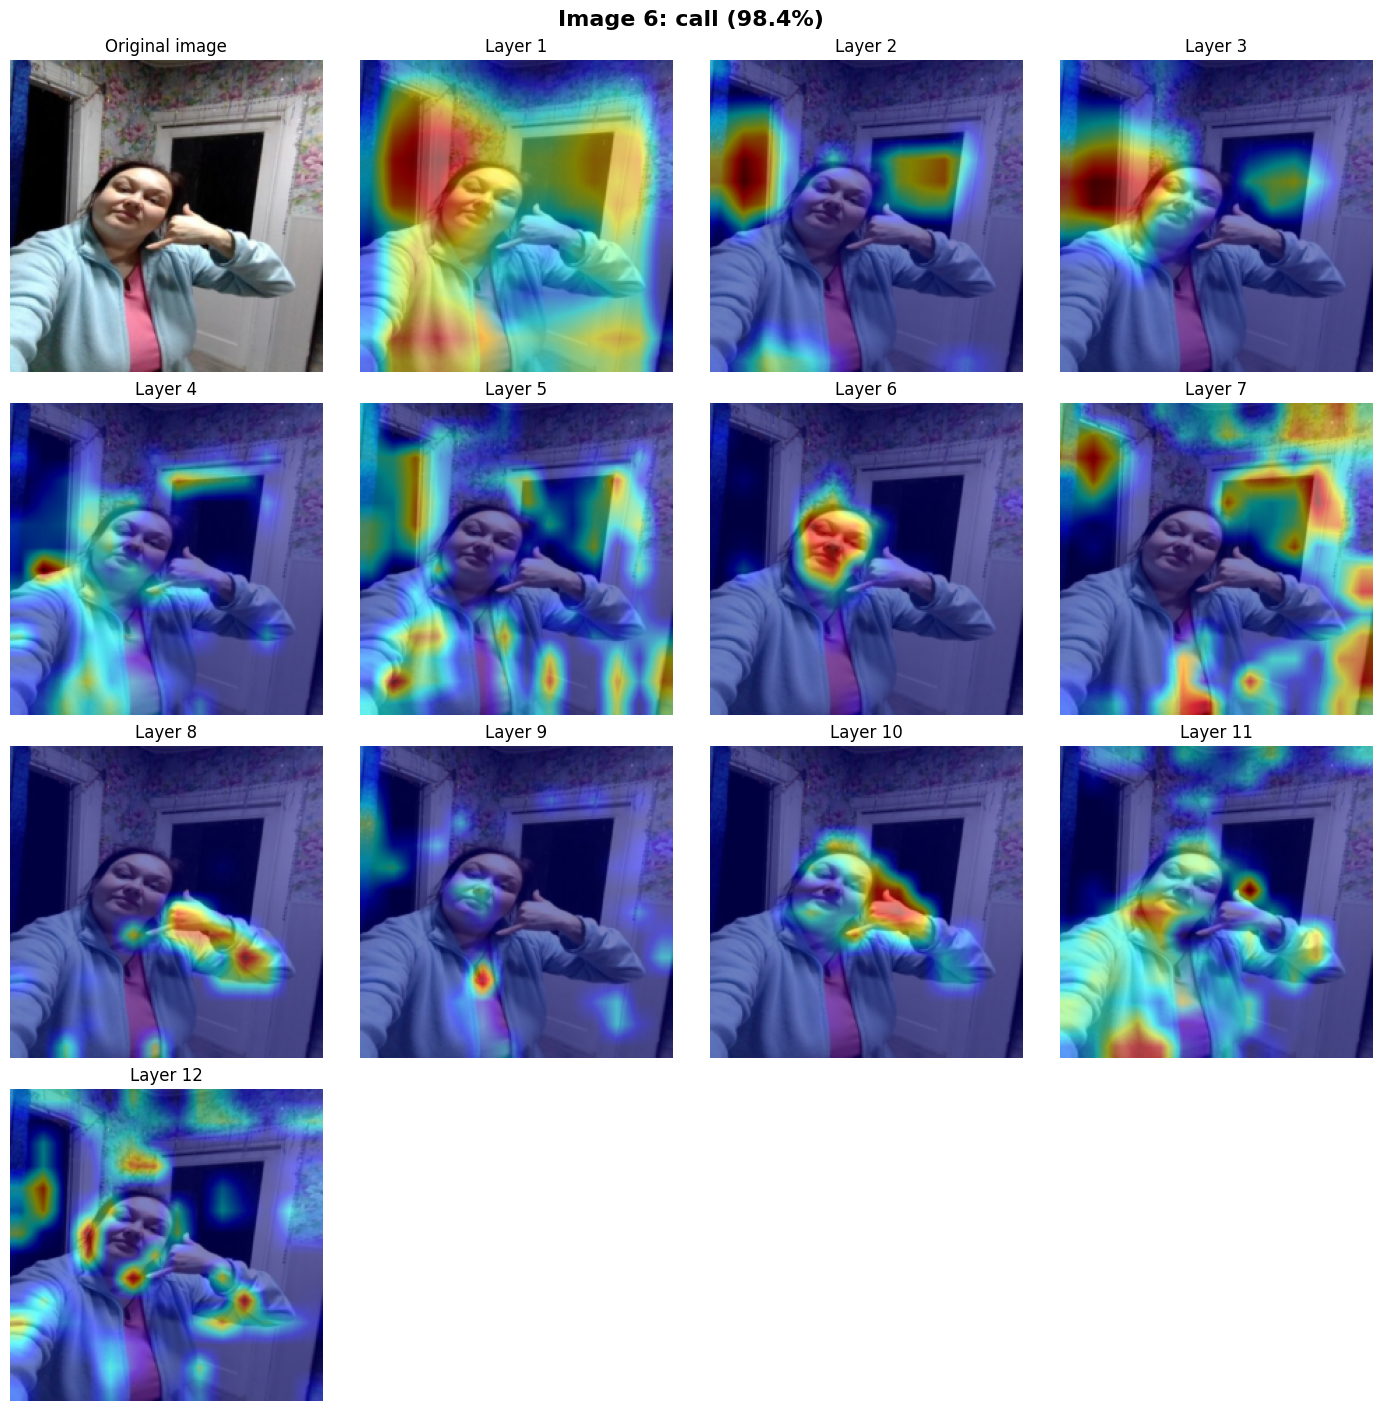

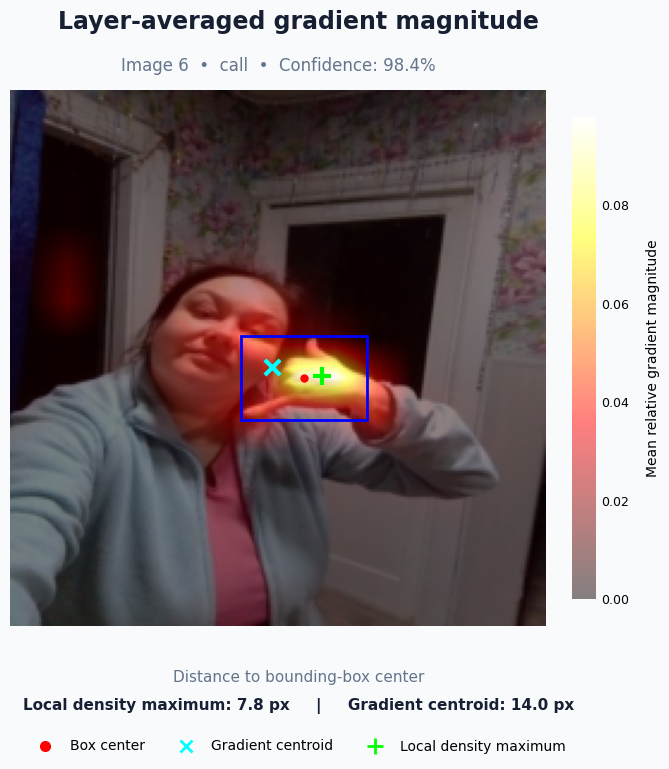

Processing image 51/500
Processing image 101/500
Processing image 151/500
Processing image 201/500


In [ ]:

def GradCAM_visualization(layers, cam_model, prepared_inputs, device, reshape_transform, bbox=None, show_cam=-1):
    layers = list(layers)
    cam_model.eval()
    mean_gradient_maps = []

    output=pd.DataFrame()
    for image_idx, prepared_input in enumerate(prepared_inputs):
        if image_idx % 50== 0:
            print(f"Processing image {image_idx + 1}/{len(prepared_inputs)}")
        input_tensor = prepared_input.to(device)

        if input_tensor.ndim == 3:
            input_tensor = input_tensor.unsqueeze(0)

        display_image = (input_tensor[0].detach().cpu().float() * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy()

        with torch.no_grad():
            class_name, predicted_class, confidence = model_prediction(input_tensor)

        predicted_class = int(predicted_class)
        confidence = float(confidence)
        normalized_layer_maps = []

        for layer_idx, layer in enumerate(layers):
            with GradCAMPlusPlus(model=cam_model, target_layers=[layer.layernorm_before], reshape_transform=reshape_transform) as cam:

                with torch.enable_grad():
                    grayscale_cam = cam(input_tensor=input_tensor, targets=[ClassifierOutputTarget(predicted_class)])[0]

                gradients = cam.activations_and_grads.gradients[0][0]
                gradient_map = gradients.detach().float().abs().mean(dim=0).cpu()
                normalized_map = gradient_map / gradient_map.sum().clamp_min(1e-12)
                normalized_layer_maps.append(normalized_map)

            if image_idx == show_cam:
                if layer_idx == 0:
                    n_plots = len(layers) + 1
                    n_cols = min(4, n_plots)
                    n_rows = (n_plots + n_cols - 1) // n_cols

                    layer_fig, layer_axes = plt.subplots(n_rows, n_cols, figsize=(3.5 * n_cols, 3.5 * n_rows), squeeze=False, constrained_layout=True)
                    layer_axes = layer_axes.ravel()
                    layer_fig.suptitle(f"Image {image_idx + 1}: {class_name} ({confidence:.1%})", fontsize=16, fontweight="bold")

                    layer_axes[0].imshow(display_image)
                    layer_axes[0].set_title("Original image")
                    layer_axes[0].axis("off")

                cam_image = show_cam_on_image(display_image, grayscale_cam, use_rgb=True, image_weight=0.5)

                layer_axes[layer_idx + 1].imshow(cam_image)
                layer_axes[layer_idx + 1].set_title(f"Layer {layer_idx + 1}")
                layer_axes[layer_idx + 1].axis("off")

                if layer_idx == len(layers) - 1:
                    for empty_ax in layer_axes[n_plots:]:
                        empty_ax.set_visible(False)

                    plt.show()


        mean_gradient_map = torch.stack(normalized_layer_maps, dim=0).mean(dim=0)
        mean_gradient_maps.append(mean_gradient_map)
        resized_map = F.interpolate(mean_gradient_map[None, None], size=display_image.shape[:2], mode="bilinear", align_corners=False)[0, 0].numpy()
        maximum_Gradient = resized_map.max()


        if image_idx == show_cam:
            fig, ax = plt.subplots(figsize=(7, 6))
            ax.imshow(display_image)
            overlay = ax.imshow(resized_map, cmap="hot", alpha=0.5, vmin=0)
            overlay.set_clim(0, maximum_Gradient)


        weights = np.asarray(resized_map, dtype=np.float64)
        total_weight = weights.sum()

        #for security, init gradient center and box center as NaN
        gradient_center_x = gradient_center_y = np.nan
        center = (np.nan, np.nan)

        if np.isfinite(total_weight) and total_weight > 0:
            yy, xx = np.indices(weights.shape)

            gradient_center_x = float((xx * weights).sum() / total_weight)
            gradient_center_y = float((yy * weights).sum() / total_weight)

            if image_idx == show_cam:
                ax.scatter(gradient_center_x, gradient_center_y, color="cyan", marker="x", s=120, linewidths=3, label="Gradient centroid", zorder=15)
                ax.legend(loc="upper right")


        window_size = 15
        gradient_tensor = torch.as_tensor(resized_map, dtype=torch.float32)[None, None]

        density_map = F.avg_pool2d(gradient_tensor, kernel_size=window_size, stride=1)[0, 0].numpy()
        density_y, density_x = np.unravel_index(np.argmax(density_map), density_map.shape)


        density_x += (window_size - 1) / 2
        density_y += (window_size - 1) / 2
        


        if bbox is not None:
            image_h, image_w = display_image.shape[:2]
            for box in bbox[image_idx]:
                x, y, w, h = map(float, box)

                center = (x * image_w + w * image_w / 2, y * image_h + h * image_h / 2)
                
                if image_idx == show_cam:
                    rect = plt.Rectangle((x * image_w, y * image_h), w * image_w, h * image_h, edgecolor="blue", facecolor="none", linewidth=2, zorder=10)
                    ax.plot(center[0], center[1], "ro", markersize=5, zorder=11)
                    ax.add_patch(rect)


        dist_center_box_local_density=np.sqrt((density_x - center[0])**2 + (density_y - center[1])**2)
        dist_center_box_gradient_center=np.sqrt((gradient_center_x - center[0])**2 + (gradient_center_y - center[1])**2)




        collect = {"dist_density": dist_center_box_local_density,
                "dist_gradient_center": dist_center_box_gradient_center,
                "Prediction": predicted_class,
                "Image Index": image_idx}
        output = pd.concat([output, pd.DataFrame([collect])], ignore_index=True)


        if image_idx == show_cam:

            fig.set_size_inches(8, 8)
            fig.patch.set_facecolor("#F8FAFC")

            ax.scatter(density_x, density_y, color="lime", marker="+", s=160, linewidths=3, zorder=15)

            fig.suptitle("Layer-averaged gradient magnitude", fontsize=17, fontweight="bold", color="#172033", y=0.97)
            ax.set_title(f"Image {image_idx + 1}  •  {class_name}  •  Confidence: {confidence:.1%}", fontsize=12, color="#64748B", pad=14)
            ax.axis("off")

            colorbar = fig.colorbar(overlay, ax=ax, fraction=0.046, pad=0.04, shrink=0.9)
            colorbar.set_label("Mean relative gradient magnitude", fontsize=10, labelpad=12)
            colorbar.ax.tick_params(labelsize=9, length=0)
            colorbar.outline.set_visible(False)

            # Replace the existing legend
            if ax.get_legend() is not None:
                ax.get_legend().remove()

            legend_handles = [
                Line2D([], [], color="red", marker="o", linestyle="None", markersize=7, label="Box center"),
                Line2D([], [], color="cyan", marker="x", linestyle="None", markersize=9, markeredgewidth=2, label="Gradient centroid"),
                Line2D([], [], color="lime", marker="+", linestyle="None", markersize=11, markeredgewidth=2, label="Local density maximum"),
            ]

            fig.text(0.5, 0.13, "Distance to bounding-box center", ha="center", fontsize=11, color="#64748B")
            fig.text(0.5, 0.095, f"Local density maximum: {dist_center_box_local_density:.1f} px     |     Gradient centroid: {dist_center_box_gradient_center:.1f} px", ha="center", fontsize=11, fontweight="bold", color="#172033")
            fig.legend(handles=legend_handles, loc="lower center", bbox_to_anchor=(0.5, 0.025), ncol=3, frameon=False, fontsize=10)

            fig.subplots_adjust(left=0.06, right=0.88, top=0.87, bottom=0.20)

            plt.show()
            plt.close(fig)

    return output


output=GradCAM_visualization(layers, cam_model, prepared_inputs, device,reshape_transform, bbox=bbox, show_cam=5)


output["ID"]=image_id

In [ ]:
analysis = output.merge(dx, on="ID", how="left")


analysis["Check"] = analysis["Prediction"] == analysis["y"]

analysis=analysis.groupby("Check")[["dist_density", "dist_gradient_center"]].mean()
analysis


,dist_density,dist_gradient_center
Check,,
False,22.424045,26.709829
True,13.504694,22.854684


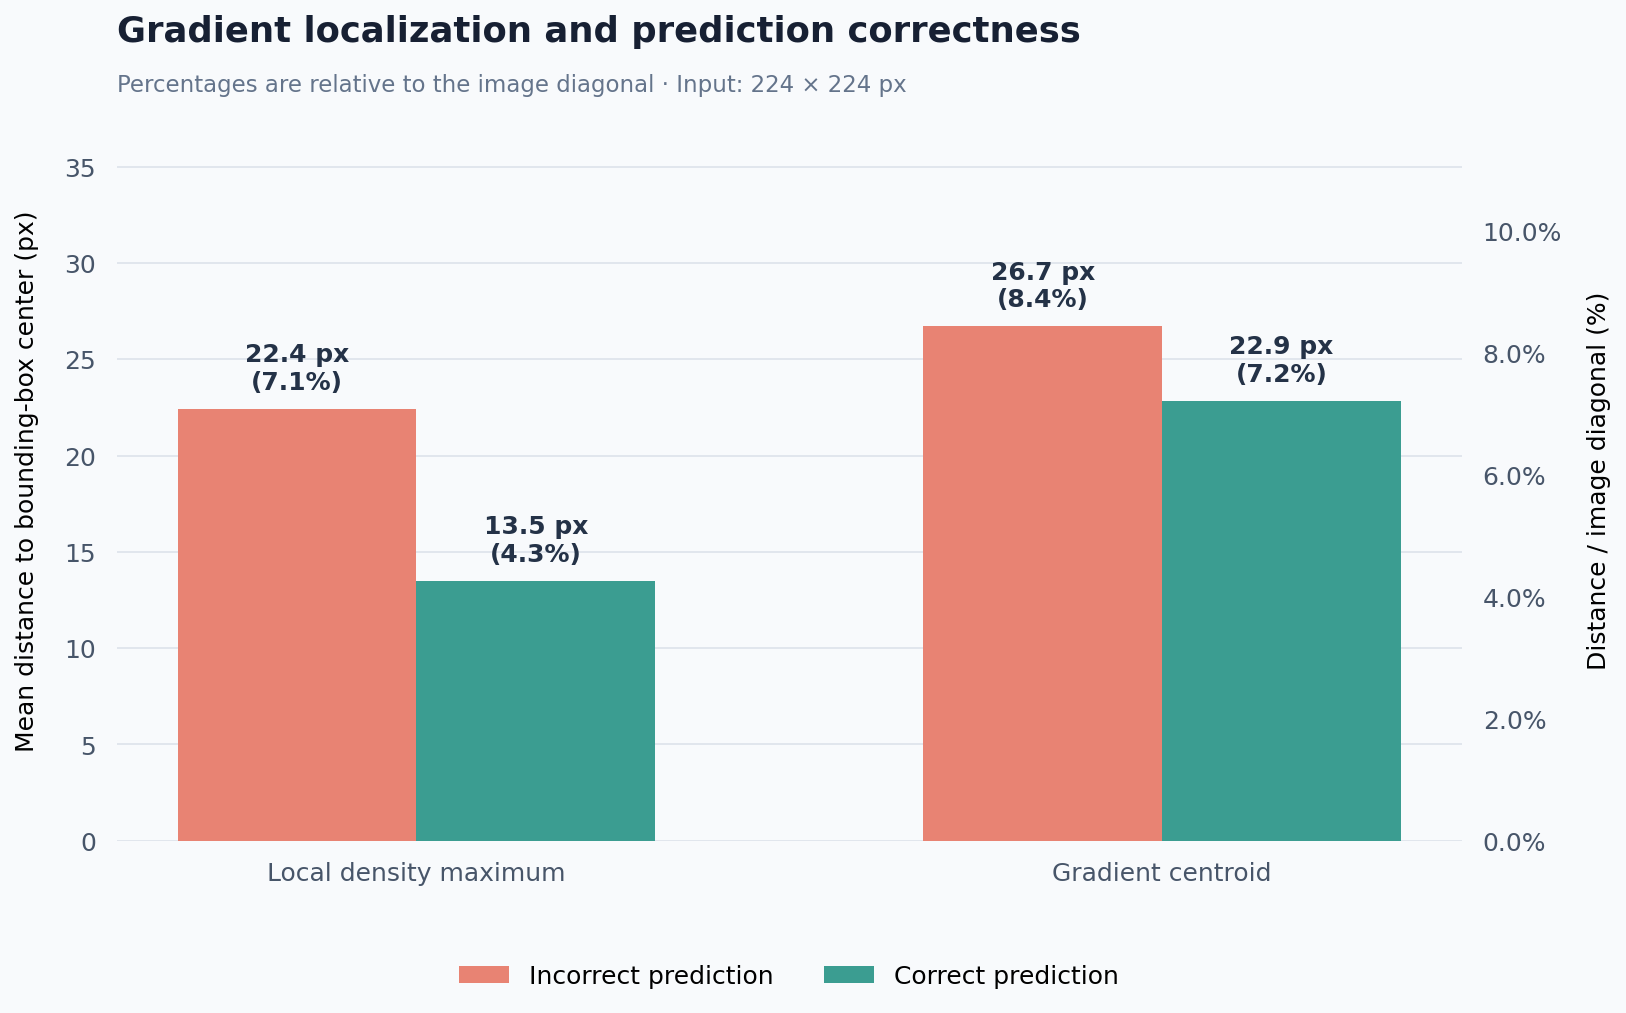

In [ ]:


columns = ["dist_density", "dist_gradient_center"]
comparison = analysis.groupby("Check")[columns].mean() if "Check" in analysis.columns else analysis[columns]
comparison = comparison.reindex([False, True])


image_h, image_w = prepared_inputs[0].shape[-2:]
image_diagonal = np.hypot(image_w, image_h)

x = np.arange(2)
width = 0.32

with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 12}):
    fig, ax = plt.subplots(figsize=(11, 7), dpi=150)
    fig.patch.set_facecolor("#F8FAFC")
    ax.set_facecolor("#F8FAFC")

    incorrect = ax.bar(x - width / 2, comparison.loc[False], width, label="Incorrect prediction", color="#E88373", zorder=3)
    correct = ax.bar(x + width / 2, comparison.loc[True], width, label="Correct prediction", color="#3B9D91", zorder=3)

    for bars in [incorrect, correct]:
        labels = [f"{bar.get_height():.1f} px\n({bar.get_height() / image_diagonal:.1%})" for bar in bars]
        ax.bar_label(bars, labels=labels, padding=7, fontsize=12, fontweight="bold", color="#243247")

    ax.set_xticks(x)
    ax.set_xticklabels(["Local density maximum", "Gradient centroid"])
    ax.set_ylabel("Mean distance to bounding-box center (px)", labelpad=12)
    ax.set_ylim(0, np.nanmax(comparison.to_numpy()) * 1.40)

    percent_axis = ax.secondary_yaxis("right", functions=(lambda px: px / image_diagonal * 100, lambda pct: pct / 100 * image_diagonal))
    percent_axis.set_ylabel("Distance / image diagonal (%)", labelpad=12)
    percent_axis.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    percent_axis.tick_params(length=0, pad=10, colors="#475569")
    percent_axis.spines["right"].set_visible(False)

    ax.set_title("Gradient localization and prediction correctness", loc="left", fontsize=17, fontweight="bold", color="#172033", pad=38)
    ax.text(0, 1.04, f"Percentages are relative to the image diagonal · Input: {image_w} × {image_h} px", transform=ax.transAxes, fontsize=11, color="#64748B")

    ax.grid(axis="y", color="#DDE3EB", linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", length=0, pad=10, colors="#475569")

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False)
    fig.tight_layout()

    plt.show()